In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import scipy.stats as stats
import warnings
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.metrics import auc, roc_curve, roc_auc_score, precision_score, recall_score, RocCurveDisplay
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay, average_precision_score
from catboost.utils import select_threshold
from matplotlib.ticker import PercentFormatter

In [90]:
nsduh_2021_2024 = pd.read_csv('C:/Users/jkirk/Downloads/nsduh_2021_2024.csv')

C:\Users\jkirk\AppData\Local\Temp\ipykernel_35292\987997185.py:1: DtypeWarning: Columns (2281: GQTYPE2) have mixed types. Specify dtype option on import or set low_memory=False.
  nsduh_2021_2024 = pd.read_csv('C:/Users/jkirk/Downloads/nsduh_2021_2024.csv')


In [128]:
X = nsduh_2021_2024[["COUTYP4", "SNRLGSVC", "IRAMDELT","AMIPY", "IRWRKSTAT18",  "IRPINC3",  "GOVTPROG"]]
y = nsduh_2021_2024["ALCFLAG"]

X = X.fillna(-1).astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75)

model = CatBoostClassifier(iterations=500, depth=8,  eval_metric='F1', silent=True)
model.fit(X_train, y_train, cat_features=["COUTYP4", "SNRLGSVC", "IRAMDELT","AMIPY", "IRWRKSTAT18",  "IRPINC3",  "GOVTPROG"])

print("Test accuracy:", model.score(X_test, y_test))
print(model.get_feature_importance(prettified=True))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

Test accuracy: 0.8196726953588821
    Feature Id  Importances
0     SNRLGSVC    21.196220
1      IRPINC3    19.770490
2     IRAMDELT    18.201023
3  IRWRKSTAT18    14.526398
4      COUTYP4    11.565639
5        AMIPY     9.687965
6     GOVTPROG     5.052266
Binary F1 Score: 0.8802


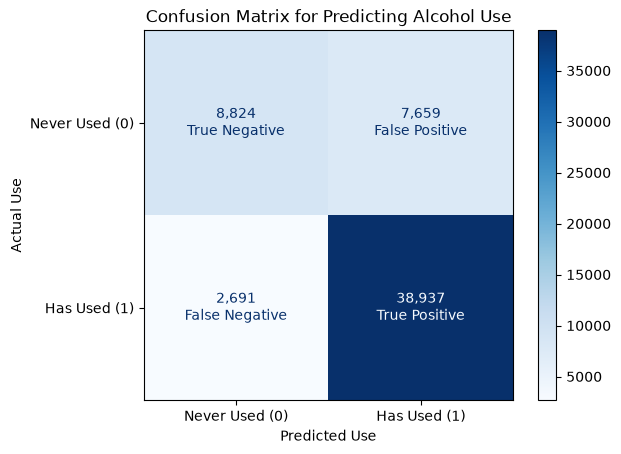

In [104]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Never Used (0)", "Has Used (1)"])
disp.plot(cmap=plt.cm.Blues, values_format=',d')

cell_labels = [["True Negative", "False Positive"],
               ["False Negative", "True Positive"]]
for i in range(2):
    for j in range(2):
        disp.text_[i, j].set_text(f"{cm[i, j]:,}\n{cell_labels[i][j]}")

plt.xlabel("Predicted Use")
plt.ylabel("Actual Use")
plt.title("Confusion Matrix for Predicting Alcohol Use")
plt.show()

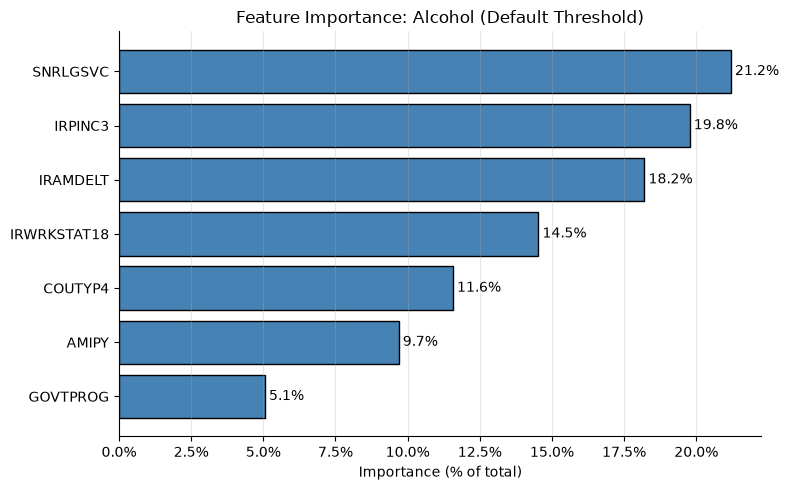

In [129]:
imp = model.get_feature_importance(prettified=True)

plt.figure(figsize=(8, 5))
bars = plt.barh(imp["Feature Id"], imp["Importances"], color="steelblue", edgecolor="black")
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(PercentFormatter())
plt.gca().spines[["top", "right"]].set_visible(False)
plt.grid(axis="x", alpha=0.3)
plt.xlabel("Importance (% of total)")
plt.title("Feature Importance: Alcohol (Default Threshold)")
plt.tight_layout()
plt.show()

In [106]:
def show_results(threshold):
    preds = (probs >= threshold).astype(int)
    cm = confusion_matrix(y_test, preds).T
    table = pd.DataFrame(cm, index=["Predicted: never used", "Predicted: has used"],
                         columns=["Actually never used", "Actually has used"])
    print()
    print("Threshold =", round(threshold, 3))
    print(table)
    print("Recall:", round(recall_score(y_test, preds), 3))
    print("Precision:", round(precision_score(y_test, preds, zero_division=0), 3))


Threshold = 0.749
                       Actually never used  Actually has used
Predicted: never used                12355              10404
Predicted: has used                   4128              31224
Recall: 0.75
Precision: 0.883


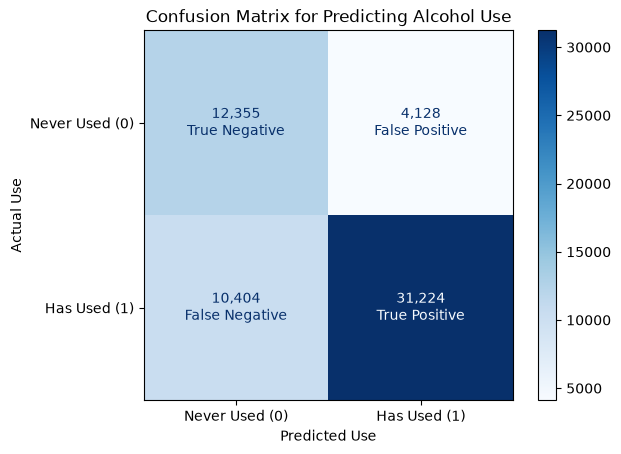


Threshold = 0.749
                       Actually never used  Actually has used
Predicted: never used                12355              10404
Predicted: has used                   4128              31224
Recall: 0.75
Precision: 0.883


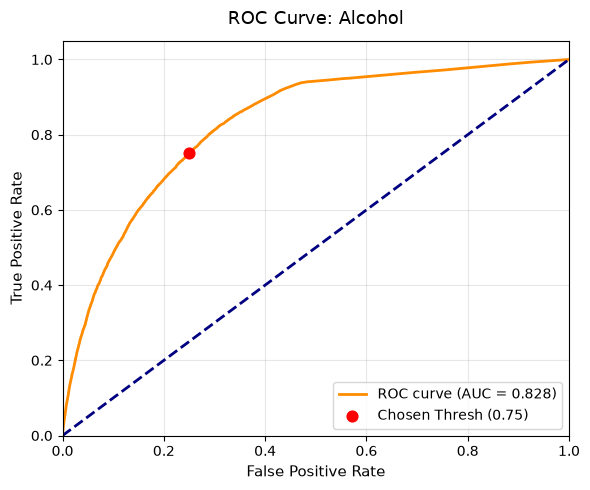

In [107]:
probs = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, probs)
position = np.argmax(tpr >= 0.75)               
chosen_threshold = thresholds[position]
show_results(chosen_threshold)

y_pred = (probs >= chosen_threshold).astype(int)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Never Used (0)", "Has Used (1)"])
disp.plot(cmap=plt.cm.Blues, values_format=',d')

cell_labels = [["True Negative", "False Positive"],
               ["False Negative", "True Positive"]]
for i in range(2):
    for j in range(2):
        disp.text_[i, j].set_text(f"{cm[i, j]:,}\n{cell_labels[i][j]}")

plt.xlabel("Predicted Use")
plt.ylabel("Actual Use")
plt.title("Confusion Matrix for Predicting Alcohol Use")
plt.show()

y_prob = model.predict_proba(X_test)[:, 1]
auc_val = roc_auc_score(y_test, y_prob)

fpr, tpr, thresholds = roc_curve(y_test, probs)
position = np.argmax(tpr >= 0.75)               
chosen_threshold = thresholds[position]
show_results(chosen_threshold)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_val:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('ROC Curve: Alcohol', fontsize=13, pad=12)
plt.scatter(fpr[position], tpr[position], color="red", s=60, zorder=5,
            label=f"Chosen Thresh ({chosen_threshold:.2f})")
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [108]:
X = nsduh_2021_2024[["COUTYP4", "SNRLGSVC", "IRAMDELT","AMIPY", "IRWRKSTAT18",  "IRPINC3",  "GOVTPROG"]]
y = nsduh_2021_2024["ALCFLAG"]

X = X.fillna(-1).astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75)

model = CatBoostClassifier(iterations=500, depth=8, use_best_model=True, silent=True)
model.fit(X_train, y_train, eval_set=(X_test, y_test), plot=False)
model.set_probability_threshold(chosen_threshold) 

print("Test accuracy:", model.score(X_test, y_test))
print(model.get_feature_importance(prettified=True))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

Test accuracy: 0.7577567069917915
    Feature Id  Importances
0      IRPINC3    28.354474
1     IRAMDELT    20.829741
2        AMIPY    19.545387
3     SNRLGSVC    17.663855
4  IRWRKSTAT18     8.241480
5      COUTYP4     2.946255
6     GOVTPROG     2.418808
Binary F1 Score: 0.8177


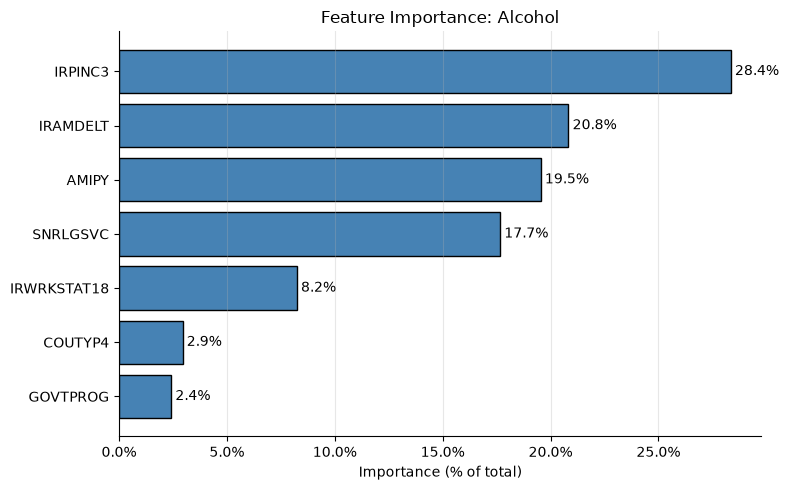

In [109]:
imp = model.get_feature_importance(prettified=True)

plt.figure(figsize=(8, 5))
bars = plt.barh(imp["Feature Id"], imp["Importances"], color="steelblue", edgecolor="black")
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(PercentFormatter())
plt.gca().spines[["top", "right"]].set_visible(False)
plt.grid(axis="x", alpha=0.3)
plt.xlabel("Importance (% of total)")
plt.title("Feature Importance: Alcohol")
plt.tight_layout()
plt.show()

In [110]:
X = nsduh_2021_2024[["COUTYP4", "SNRLGSVC", "IRAMDELT","AMIPY", "IRWRKSTAT18",  "IRPINC3",  "GOVTPROG"]]
y = nsduh_2021_2024["MRJFLAG"]

X = X.fillna(-1).astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75)

model = CatBoostClassifier(iterations=500, depth=8, silent=True)
model.fit(X_train, y_train, cat_features=["COUTYP4", "SNRLGSVC", "IRAMDELT","AMIPY", "IRWRKSTAT18",  "IRPINC3",  "GOVTPROG"])

print("Test accuracy:", model.score(X_test, y_test))
print(model.get_feature_importance(prettified=True))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

Test accuracy: 0.6685481234189741
    Feature Id  Importances
0     SNRLGSVC    25.130675
1      IRPINC3    18.706120
2     IRAMDELT    14.320348
3  IRWRKSTAT18    13.205506
4        AMIPY    12.888145
5      COUTYP4    11.415010
6     GOVTPROG     4.334198
Binary F1 Score: 0.6286


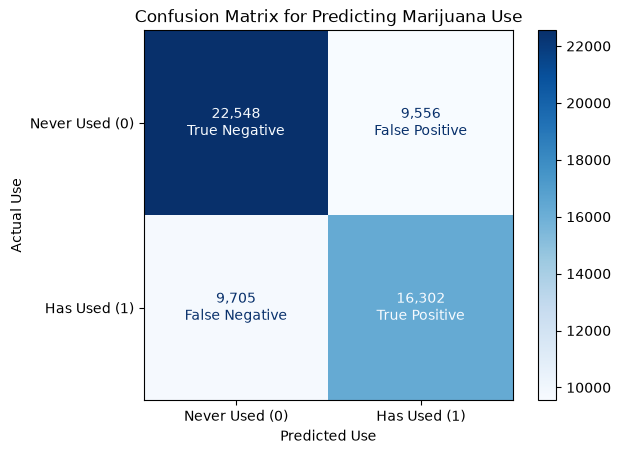

In [111]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Never Used (0)", "Has Used (1)"])
disp.plot(cmap=plt.cm.Blues, values_format=',d')

cell_labels = [["True Negative", "False Positive"],
               ["False Negative", "True Positive"]]
for i in range(2):
    for j in range(2):
        disp.text_[i, j].set_text(f"{cm[i, j]:,}\n{cell_labels[i][j]}")

plt.xlabel("Predicted Use")
plt.ylabel("Actual Use")
plt.title("Confusion Matrix for Predicting Marijuana Use")
plt.show()

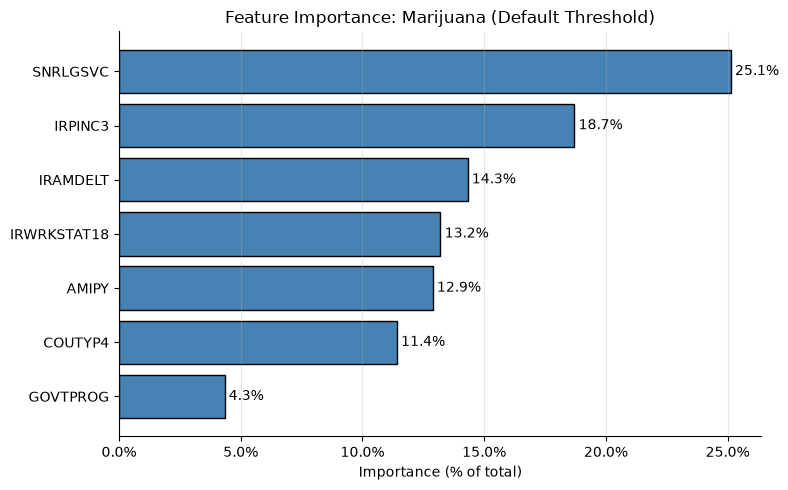

In [112]:
imp = model.get_feature_importance(prettified=True)

plt.figure(figsize=(8, 5))
bars = plt.barh(imp["Feature Id"], imp["Importances"], color="steelblue", edgecolor="black")
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(PercentFormatter())
plt.gca().spines[["top", "right"]].set_visible(False)
plt.grid(axis="x", alpha=0.3)
plt.xlabel("Importance (% of total)")
plt.title("Feature Importance: Marijuana (Default Threshold)")
plt.tight_layout()
plt.show()


Threshold = 0.437
                       Actually never used  Actually has used
Predicted: never used                18795               6470
Predicted: has used                  13309              19537
Recall: 0.751
Precision: 0.595


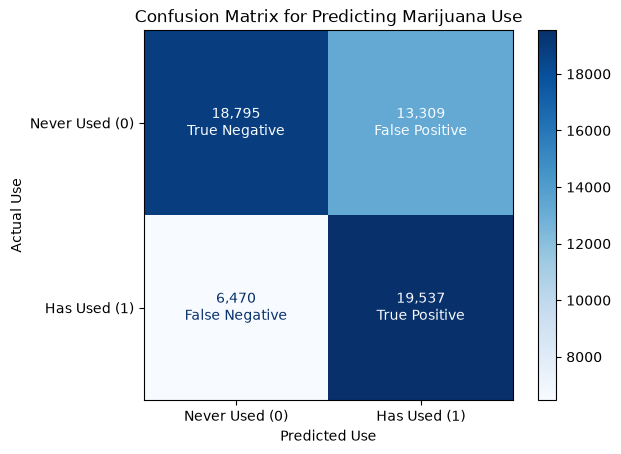


Threshold = 0.437
                       Actually never used  Actually has used
Predicted: never used                18795               6470
Predicted: has used                  13309              19537
Recall: 0.751
Precision: 0.595


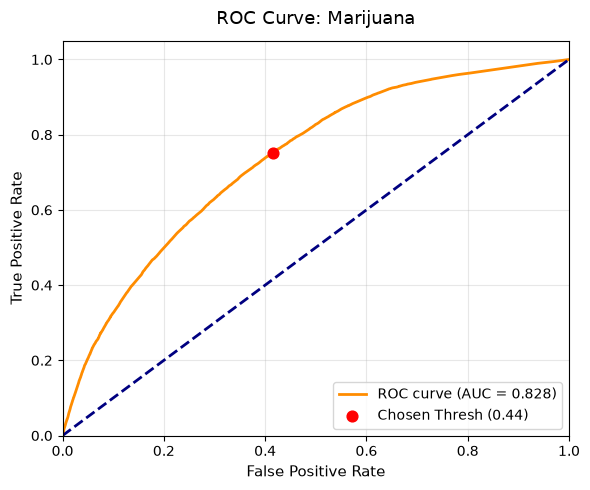

In [113]:
probs = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, probs)
position = np.argmax(tpr >= 0.75)               
chosen_threshold = thresholds[position]
show_results(chosen_threshold)

y_pred = (probs >= chosen_threshold).astype(int)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Never Used (0)", "Has Used (1)"])
disp.plot(cmap=plt.cm.Blues, values_format=',d')

cell_labels = [["True Negative", "False Positive"],
               ["False Negative", "True Positive"]]
for i in range(2):
    for j in range(2):
        disp.text_[i, j].set_text(f"{cm[i, j]:,}\n{cell_labels[i][j]}")

plt.xlabel("Predicted Use")
plt.ylabel("Actual Use")
plt.title("Confusion Matrix for Predicting Marijuana Use")
plt.show()


fpr, tpr, thresholds = roc_curve(y_test, probs)
position = np.argmax(tpr >= 0.75)               
chosen_threshold = thresholds[position]
show_results(chosen_threshold)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_val:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('ROC Curve: Marijuana', fontsize=13, pad=12)
plt.scatter(fpr[position], tpr[position], color="red", s=60, zorder=5,
            label=f"Chosen Thresh ({chosen_threshold:.2f})")
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [114]:
X = nsduh_2021_2024[["COUTYP4", "SNRLGSVC", "IRAMDELT","AMIPY", "IRWRKSTAT18",  "IRPINC3",  "GOVTPROG"]]
y = nsduh_2021_2024["MRJFLAG"]

X = X.fillna(-1).astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75)

model = CatBoostClassifier(iterations=500, depth=8, use_best_model=True, silent=True)
model.fit(X_train, y_train, eval_set=(X_test, y_test), plot=False)
model.set_probability_threshold(chosen_threshold) 

print("Test accuracy:", model.score(X_test, y_test))
print(model.get_feature_importance(prettified=True))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

Test accuracy: 0.6591523119547074
    Feature Id  Importances
0     SNRLGSVC    29.703904
1        AMIPY    19.782142
2     IRAMDELT    18.724847
3  IRWRKSTAT18    12.343439
4      IRPINC3    11.025499
5     GOVTPROG     5.540190
6      COUTYP4     2.879979
Binary F1 Score: 0.6638


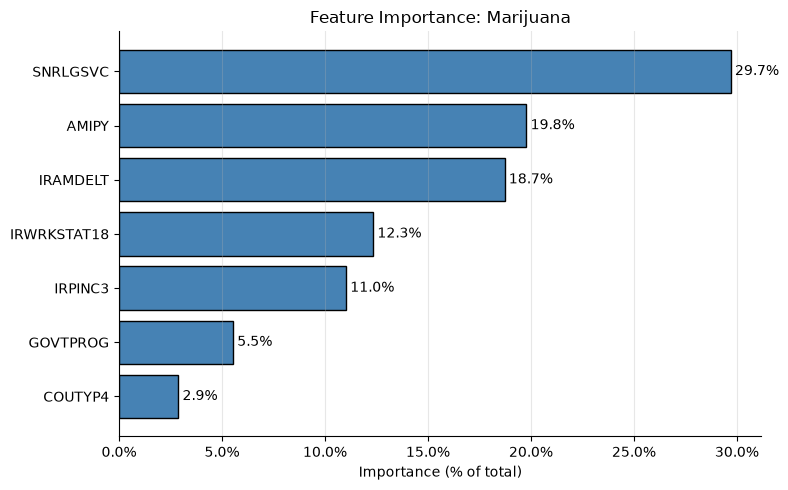

In [115]:
imp = model.get_feature_importance(prettified=True)

plt.figure(figsize=(8, 5))
bars = plt.barh(imp["Feature Id"], imp["Importances"], color="steelblue", edgecolor="black")
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(PercentFormatter())
plt.gca().spines[["top", "right"]].set_visible(False)
plt.grid(axis="x", alpha=0.3)
plt.xlabel("Importance (% of total)")
plt.title("Feature Importance: Marijuana")
plt.tight_layout()
plt.show()

In [116]:
X = nsduh_2021_2024[["COUTYP4", "SNRLGSVC", "IRAMDELT","AMIPY", "IRWRKSTAT18",  "IRPINC3",  "GOVTPROG"]]
y = nsduh_2021_2024["COCFLAG"]

X = X.fillna(-1).astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75)

model = CatBoostClassifier(iterations=500, depth=8, silent=True)
model.fit(X_train, y_train, cat_features=["COUTYP4", "SNRLGSVC", "IRAMDELT","AMIPY", "IRWRKSTAT18",  "IRPINC3",  "GOVTPROG"])

print("Test accuracy:", model.score(X_test, y_test))
print(model.get_feature_importance(prettified=True))

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

Test accuracy: 0.8853573333792225
    Feature Id  Importances
0     IRAMDELT    48.730323
1     SNRLGSVC    12.750974
2      IRPINC3    12.160445
3  IRWRKSTAT18     8.223198
4      COUTYP4     8.068981
5        AMIPY     6.401134
6     GOVTPROG     3.664945
Binary F1 Score: 0.1936


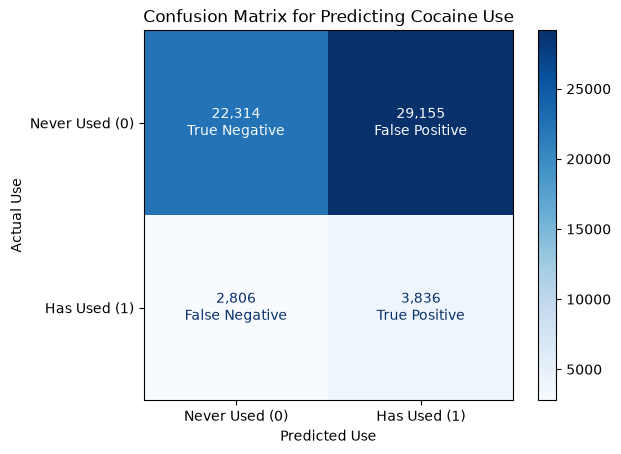

In [117]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Never Used (0)", "Has Used (1)"])
disp.plot(cmap=plt.cm.Blues, values_format=',d')

cell_labels = [["True Negative", "False Positive"],
               ["False Negative", "True Positive"]]
for i in range(2):
    for j in range(2):
        disp.text_[i, j].set_text(f"{cm[i, j]:,}\n{cell_labels[i][j]}")

plt.xlabel("Predicted Use")
plt.ylabel("Actual Use")
plt.title("Confusion Matrix for Predicting Cocaine Use")
plt.show()

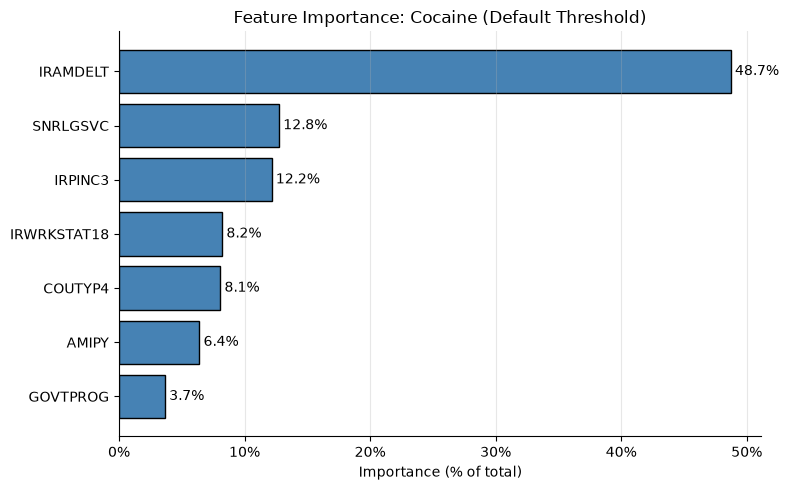

In [118]:
imp = model.get_feature_importance(prettified=True)

plt.figure(figsize=(8, 5))
bars = plt.barh(imp["Feature Id"], imp["Importances"], color="steelblue", edgecolor="black")
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(PercentFormatter())
plt.gca().spines[["top", "right"]].set_visible(False)
plt.grid(axis="x", alpha=0.3)
plt.xlabel("Importance (% of total)")
plt.title("Feature Importance: Cocaine (Default Threshold)")
plt.tight_layout()
plt.show()


Threshold = 0.118
                       Actually never used  Actually has used
Predicted: never used                28815               1636
Predicted: has used                  22654               5006
Recall: 0.754
Precision: 0.181


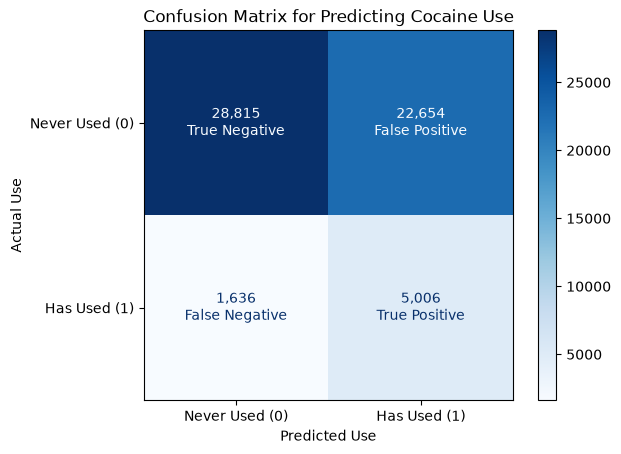


Threshold = 0.118
                       Actually never used  Actually has used
Predicted: never used                28815               1636
Predicted: has used                  22654               5006
Recall: 0.754
Precision: 0.181


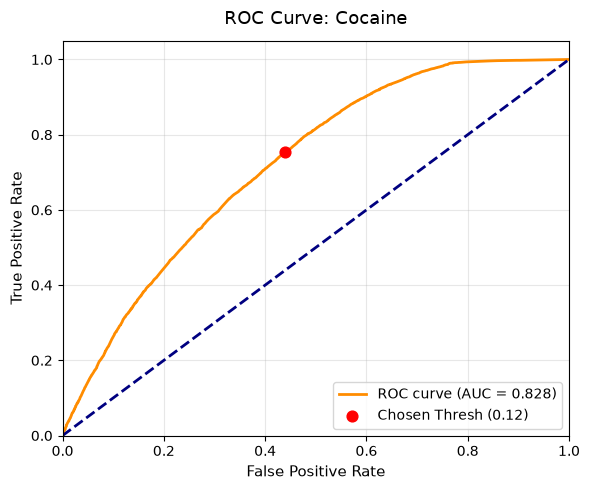

In [119]:
probs = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, probs)
position = np.argmax(tpr >= 0.75)               
chosen_threshold = thresholds[position]
show_results(chosen_threshold)

y_pred = (probs >= chosen_threshold).astype(int)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Never Used (0)", "Has Used (1)"])
disp.plot(cmap=plt.cm.Blues, values_format=',d')

cell_labels = [["True Negative", "False Positive"],
               ["False Negative", "True Positive"]]
for i in range(2):
    for j in range(2):
        disp.text_[i, j].set_text(f"{cm[i, j]:,}\n{cell_labels[i][j]}")

plt.xlabel("Predicted Use")
plt.ylabel("Actual Use")
plt.title("Confusion Matrix for Predicting Cocaine Use")
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, probs)
position = np.argmax(tpr >= 0.75)               
chosen_threshold = thresholds[position]
show_results(chosen_threshold)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_val:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('ROC Curve: Cocaine', fontsize=13, pad=12)
plt.scatter(fpr[position], tpr[position], color="red", s=60, zorder=5,
            label=f"Chosen Thresh ({chosen_threshold:.2f})")
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [120]:
X = nsduh_2021_2024[["COUTYP4", "SNRLGSVC", "IRAMDELT","AMIPY", "IRWRKSTAT18",  "IRPINC3",  "GOVTPROG"]]
y = nsduh_2021_2024["COCFLAG"]

X = X.fillna(-1).astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75)

model = CatBoostClassifier(iterations=500, depth=8, use_best_model=True, silent=True)
model.fit(X_train, y_train, eval_set=(X_test, y_test), plot=False)
model.set_probability_threshold(chosen_threshold) 

print("Test accuracy:", model.score(X_test, y_test))
print(model.get_feature_importance(prettified=True))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

Test accuracy: 0.5743490905336339
    Feature Id  Importances
0     IRAMDELT    62.732606
1        AMIPY    11.496913
2     SNRLGSVC     8.263355
3      IRPINC3     6.153631
4     GOVTPROG     5.096434
5      COUTYP4     3.826645
6  IRWRKSTAT18     2.430416
Binary F1 Score: 0.2962


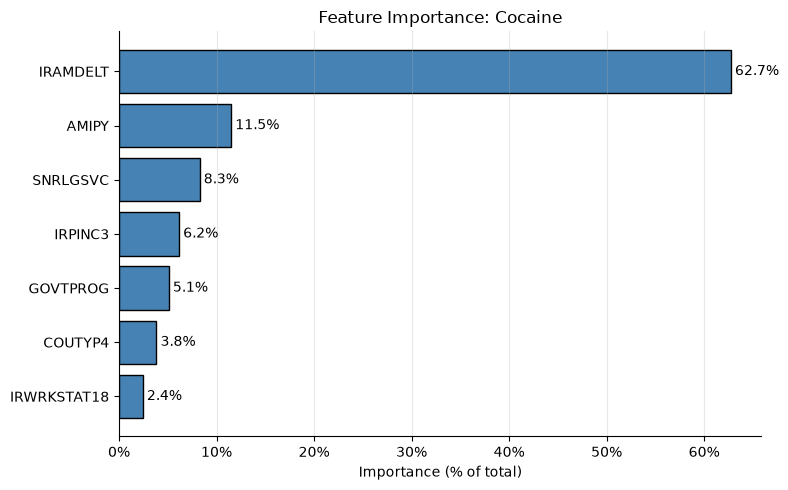

In [121]:
imp = model.get_feature_importance(prettified=True)

plt.figure(figsize=(8, 5))
bars = plt.barh(imp["Feature Id"], imp["Importances"], color="steelblue", edgecolor="black")
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(PercentFormatter())
plt.gca().spines[["top", "right"]].set_visible(False)
plt.grid(axis="x", alpha=0.3)
plt.xlabel("Importance (% of total)")
plt.title("Feature Importance: Cocaine")
plt.tight_layout()
plt.show()

In [122]:
X = nsduh_2021_2024[["COUTYP4", "SNRLGSVC", "IRAMDELT","AMIPY", "IRWRKSTAT18",  "IRPINC3",  "GOVTPROG"]]
y = nsduh_2021_2024["HERFLAG"]

X = X.fillna(-1).astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75)

model = CatBoostClassifier(iterations=500, depth=8, use_best_model=True, silent=True)
model.fit(X_train, y_train, eval_set=(X_test, y_test), plot=False)

print("Test accuracy:", model.score(X_test, y_test))
print(model.get_feature_importance(prettified=True))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

Test accuracy: 0.9802102872089622
    Feature Id  Importances
0  IRWRKSTAT18    37.684038
1        AMIPY    20.802820
2     IRAMDELT    14.431196
3     GOVTPROG     9.984817
4     SNRLGSVC     6.143135
5      COUTYP4     6.108784
6      IRPINC3     4.845210
Binary F1 Score: 0.0000


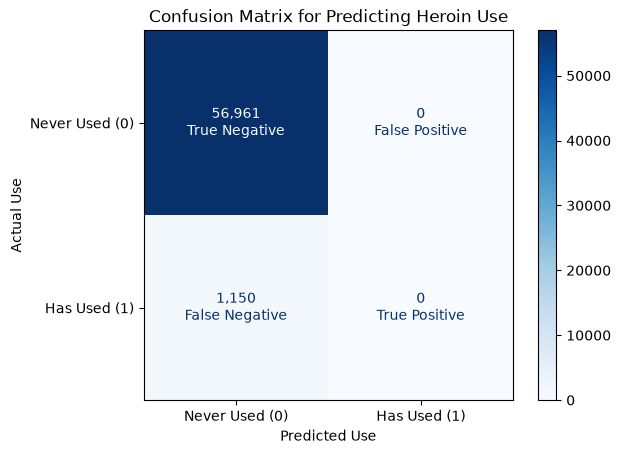

In [123]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Never Used (0)", "Has Used (1)"])
disp.plot(cmap=plt.cm.Blues, values_format=',d')

cell_labels = [["True Negative", "False Positive"],
               ["False Negative", "True Positive"]]
for i in range(2):
    for j in range(2):
        disp.text_[i, j].set_text(f"{cm[i, j]:,}\n{cell_labels[i][j]}")

plt.xlabel("Predicted Use")
plt.ylabel("Actual Use")
plt.title("Confusion Matrix for Predicting Heroin Use")
plt.show()

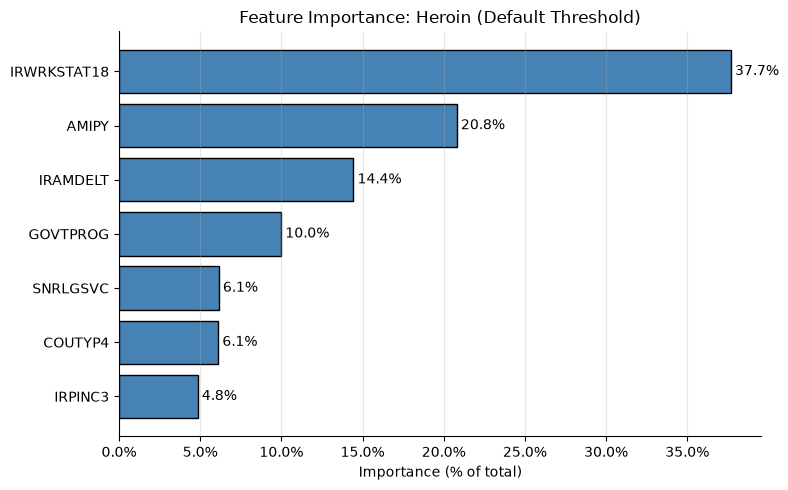

In [124]:
imp = model.get_feature_importance(prettified=True)

plt.figure(figsize=(8, 5))
bars = plt.barh(imp["Feature Id"], imp["Importances"], color="steelblue", edgecolor="black")
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(PercentFormatter())
plt.gca().spines[["top", "right"]].set_visible(False)
plt.grid(axis="x", alpha=0.3)
plt.xlabel("Importance (% of total)")
plt.title("Feature Importance: Heroin (Default Threshold)")
plt.tight_layout()
plt.show()


Threshold = 0.017
                       Actually never used  Actually has used
Predicted: never used                36240                287
Predicted: has used                  20721                863
Recall: 0.75
Precision: 0.04


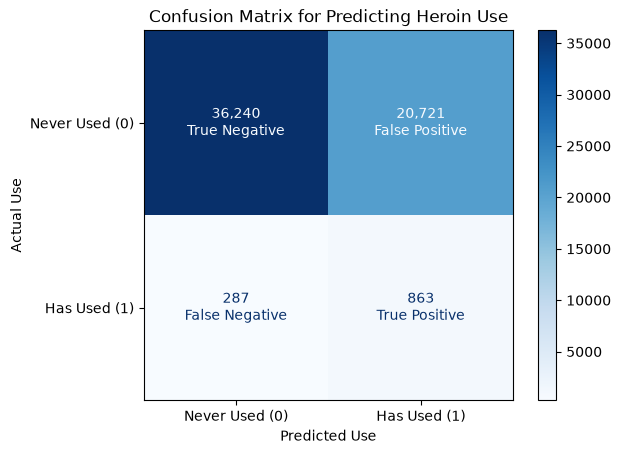


Threshold = 0.017
                       Actually never used  Actually has used
Predicted: never used                36240                287
Predicted: has used                  20721                863
Recall: 0.75
Precision: 0.04


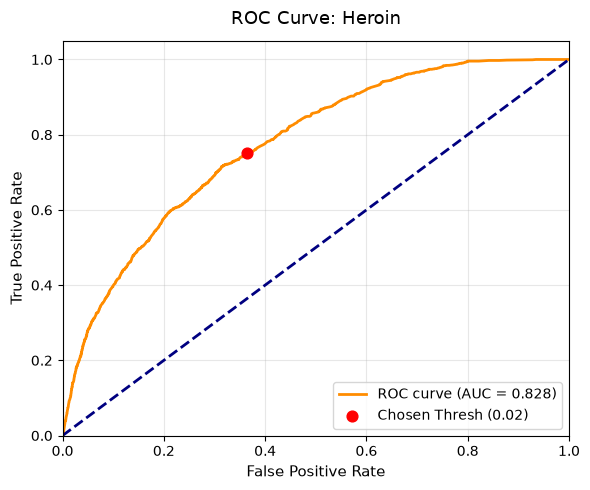

In [125]:
probs = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, probs)
position = np.argmax(tpr >= 0.75)               
chosen_threshold = thresholds[position]
show_results(chosen_threshold)

y_pred = (probs >= chosen_threshold).astype(int)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Never Used (0)", "Has Used (1)"])
disp.plot(cmap=plt.cm.Blues, values_format=',d')

cell_labels = [["True Negative", "False Positive"],
               ["False Negative", "True Positive"]]
for i in range(2):
    for j in range(2):
        disp.text_[i, j].set_text(f"{cm[i, j]:,}\n{cell_labels[i][j]}")

plt.xlabel("Predicted Use")
plt.ylabel("Actual Use")
plt.title("Confusion Matrix for Predicting Heroin Use")
plt.show()


fpr, tpr, thresholds = roc_curve(y_test, probs)
position = np.argmax(tpr >= 0.75)               
chosen_threshold = thresholds[position]
show_results(chosen_threshold)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_val:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('ROC Curve: Heroin', fontsize=13, pad=12)
plt.scatter(fpr[position], tpr[position], color="red", s=60, zorder=5,
            label=f"Chosen Thresh ({chosen_threshold:.2f})")
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [126]:
X = nsduh_2021_2024[["COUTYP4", "SNRLGSVC", "IRAMDELT","AMIPY", "IRWRKSTAT18",  "IRPINC3",  "GOVTPROG"]]
y = nsduh_2021_2024["HERFLAG"]

X = X.fillna(-1).astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75)

model = CatBoostClassifier(iterations=500, depth=8, use_best_model=True, silent=True)
model.fit(X_train, y_train, eval_set=(X_test, y_test), plot=False)
model.set_probability_threshold(chosen_threshold) 

print("Test accuracy:", model.score(X_test, y_test))
print(model.get_feature_importance(prettified=True))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

Test accuracy: 0.6507717987988505
    Feature Id  Importances
0  IRWRKSTAT18    36.983805
1        AMIPY    22.163642
2     IRAMDELT    12.303719
3     GOVTPROG    10.429135
4     SNRLGSVC     6.813947
5      IRPINC3     5.909738
6      COUTYP4     5.396013
Binary F1 Score: 0.0745


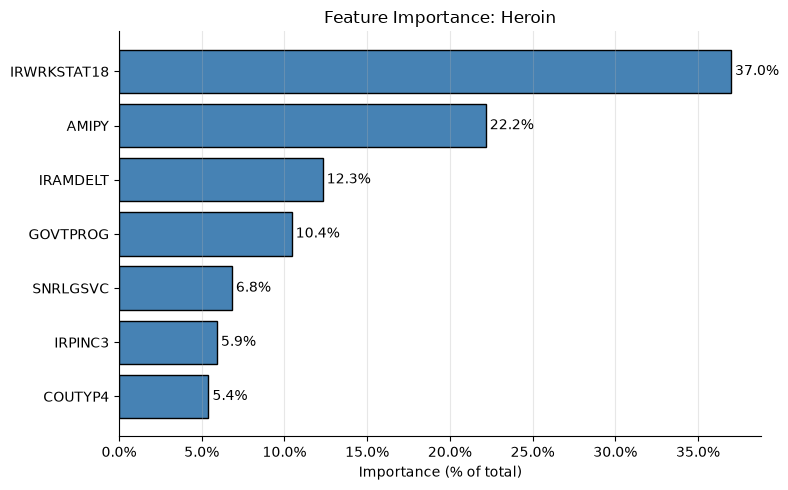

In [127]:
imp = model.get_feature_importance(prettified=True)

plt.figure(figsize=(8, 5))
bars = plt.barh(imp["Feature Id"], imp["Importances"], color="steelblue", edgecolor="black")
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(PercentFormatter())
plt.gca().spines[["top", "right"]].set_visible(False)
plt.grid(axis="x", alpha=0.3)
plt.xlabel("Importance (% of total)")
plt.title("Feature Importance: Heroin")
plt.tight_layout()
plt.show()